### Baseline Models

In [1]:
import numpy

from util.data_aquisition import generate

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2015-2016
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019


In [3]:
import pandas as pd
import numpy as np
import math
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.model_selection import KFold
from sklearn.calibration import calibration_curve, CalibrationDisplay
from scipy.stats import percentileofscore

In [4]:
Empty_Net = []
Game_ID = []
Game_Type = []
Event_ID = []
Event_Type = []
Power_Game = []
Team_Attack = []
Coordinate_X = []
Coordinate_Y = []
Period = []
Period_Time = []
Time = []
Shooters = []
Scorers = []
Goalies = []
Shoot_type = []
Home = []
Away = []
Home_Rink = []
#Last Event Features
Last_Event_ID = []
Last_Event_Type = []
Last_Coordinate_X = []
Last_Coordinate_Y = []
Last_Period = []
Last_Period_Time = []
Last_Time = []

for a in range(len(data.data)):
    for b in range(len(data.data[a]['data'])):
        for i in range(len(data.data[a]['data'][b]['liveData']['plays']['allPlays'])):
            if data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result']['event'] == 'Shot' or data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result']['event'] == 'Goal':
                #Ici ajouter les données relatives au last event (type_last, x_last etc..) en se référant
                #À i-1 au lieu de i.
                Last_Event_ID.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['about']['eventIdx'])
                Last_Event_Type.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['result']['event'])
                Last_Coordinate_X.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['coordinates'].get('x', np.nan))
                Last_Coordinate_Y.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['coordinates'].get('y', np.nan))
                Last_Period.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['about']['period'])
                Last_Period_Time.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['about']['periodTime'])
                Last_Time.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i-1]['about']['dateTime'])
                #
                Game_ID.append(data.data[a]['data'][b]['gamePk'])
                Game_Type.append(data.data[a]['data'][b]['gameData']['game']['type'])
                Event_ID.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['about']['eventIdx'])
                Event_Type.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result']['event'])
                Home.append(data.data[a]['data'][b]['gameData']['teams']['home']['name'])
                Away.append(data.data[a]['data'][b]['gameData']['teams']['away']['name'])
                if data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['about']['periodType'] =='SHOOTOUT':
                    Home_Rink.append(np.nan)
                else:
                    Home_Rink.append(data.data[a]['data'][b]['liveData']['linescore']['periods'][data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['about']['period']-1]['home'].get('rinkSide', np.nan))

                if 'strength' in data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result'].keys():
                    Power_Game.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result']['strength']['name'])
                else:
                    Power_Game.append(np.nan)

                if 'emptyNet' in data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result'].keys():
                    Empty_Net.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result']['emptyNet'])
                else:
                    Empty_Net.append(np.nan)
                Team_Attack.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['team']['name'])
                Coordinate_X.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['coordinates'].get('x', np.nan))
                Coordinate_Y.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['coordinates'].get('y', np.nan))
                Period.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['about']['period'])
                Period_Time.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['about']['periodTime'])
                Time.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['about']['dateTime'])
                Shoot_type.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['result'].get('secondaryType', np.nan))

                for j in range(len(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'])):
                        if data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'][j]['playerType'] == 'Shooter':
                            Shooters.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'][j]['player']['fullName'])
                        if data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'][j]['playerType'] == 'Scorer':
                            Shooters.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'][j]['player']['fullName'])
                        if data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'][j]['playerType'] == 'Goalie':
                            Goalies.append(data.data[a]['data'][b]['liveData']['plays']['allPlays'][i]['players'][j]['player']['fullName'])

            if len(Goalies) < len(Game_ID):
                Goalies.append(np.nan)


data_game = {'Game_ID': Game_ID, 'Game_Type': Game_Type, 'Event_ID': Event_ID, 'Last_Event_ID': Last_Event_ID, 'Home_Team': Home, 'Home_Rink': Home_Rink, 'Away_Team': Away, 'Event_Type': Event_Type, 'Last_Event_Type': Last_Event_Type, 'Shoot_Type': Shoot_type, 'Time': Time, 'Period': Period, 'Last_Period': Last_Period, 'Period_Time': Period_Time, 'Last_Period_Time': Last_Period_Time, 'Team_Attack': Team_Attack, 'Power_Game': Power_Game, 'Empty_Net': Empty_Net, 'Shooters_scorer': Shooters, 'Goalies': Goalies, 'X_Coordinate': Coordinate_X, 'Last_Coordinate_X': Last_Coordinate_X, 'Y_Coordinate': Coordinate_Y, 'Last_Coordinate_Y': Last_Coordinate_Y}
df = pd.DataFrame(data_game)

# Convert Period times to datetime
df['Period_Time'] = pd.to_datetime(df['Period_Time'])
df['Last_Period_Time'] = pd.to_datetime(df['Last_Period_Time'])
# Broadcasting: subtract last period time to period time
df['Time_Between_Events']= df['Period_Time']-df['Last_Period_Time']
#Only display in seconds, wierd cause here seconds where treated as minutes so divided by 60
df['Time_Between_Events'] = (df['Time_Between_Events'].astype('timedelta64[s]')/60).astype(str)

def transform_X(row):
    '''
    Given a row of the original data frame, this function transforms the coordinate X depending on the position of
    the teams in the rink. Since at the end the data is presented in a half-rink (we arbitrarily choose that
    this is the right half of the rink), when the attacking team plays on the right side of the rink , i.e
    the opponent's goal is on the left side, we need to flip the x coordinate.
    '''
    if str(row['Home_Rink']) == 'nan': #In case the rinkside information is not available, we assume the shot
        #is taken from the side that is the closest to the opponent's goal.
        return np.absolute(row['X_Coordinate'])

    else: #Otherwise we use rinkside information to determine whether to flip X coordinate as described above.
        if row['Home_Team'] == row['Team_Attack']:
            if row['Home_Rink'] == 'right':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']
        else:
            if row['Home_Rink'] == 'left':
                return -(row['X_Coordinate'])
            else:
                return row['X_Coordinate']

# Transform X coordinates to one side of the rink
df['X_Transformed'] = df.apply(transform_X, axis=1)

def transform_last_X(row):
    '''
    Given a row of the original data frame, this function transforms the Last coordinate X depending on the position of
    the teams in the rink. Since at the end the data is presented in a half-rink (we arbitrarily choose that
    this is the right half of the rink), when the attacking team plays on the right side of the rink , i.e
    the opponent's goal is on the left side, we need to flip the x coordinate.
    '''
    if str(row['Home_Rink']) == 'nan': #In case the rinkside information is not available, we assume the shot
        #is taken from the side that is the closest to the opponent's goal.
        return np.absolute(row['Last_Coordinate_X'])

    else: #Otherwise we use rinkside information to determine whether to flip X coordinate as described above.
        if row['Home_Team'] == row['Team_Attack']:
            if row['Home_Rink'] == 'right':
                return -(row['Last_Coordinate_X'])
            else:
                return row['Last_Coordinate_X']
        else:
            if row['Home_Rink'] == 'left':
                return -(row['Last_Coordinate_X'])
            else:
                return row['Last_Coordinate_X']

# Transform Last Coordinates X to one side of the rink
df['Last_X_Transformed'] = df.apply(transform_last_X, axis=1)

def get_distance_net(row):
    '''
    Given a row of the original dataframe, this function computes the distance between the shot and the net
    '''
    return ((89- row['X_Transformed'])**2+(0-row['Y_Coordinate'])**2)**(1/2)

df['Distance_Net']=df.apply(get_distance_net, axis=1)

def get_distance(row):
    ''' Given a row of the original dataframe, this function computes the distance between one event and its preceding event'''
    return ((row['X_Coordinate']-row['Last_Coordinate_X'])**2+(row['Y_Coordinate']-row['Last_Coordinate_Y'])**2)**(1/2)

# Get the distance between all pairs of events and preceding events
df['Distance']= df.apply(get_distance, axis=1)

# Create a boolean column testing whether the last event type was a shot
df['Rebond'] = df['Last_Event_Type'] == 'Shot'

def get_angle(row):
    '''
    Given a row on the original dataframe, this function computes the angle of the shot. It first tests whether the last event was a Rebond. If false, it returns NAN. If true, it then tests whether the X_Transformed coordinate of the event is 89 (the x coordinate of the net). If also true, it returns an angle of either -90 or 90 degrees depending on its y coordinate. If false, it computes the angle according to the right triangle properties.
    '''
    # if row['Rebond']:
    if row['X_Transformed'] ==89:
        return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))
    else :
        return np.arctan((row['Y_Coordinate']/(89-row['X_Transformed'])))*180/math.pi
    # else:
    #     return np.nan

#Set the angles of the events (Wierd message appears...)
df['Angle'] = df.apply(get_angle, axis = 1)

def get_last_angle(row):
    '''
    Given a row on the original dataframe, this function computes the angle of the last shot. It first tests whether the last event was a Rebond. If false, it returns NAN. If true, it then tests whether the Last_X_Transformed coordinate of the event is 89 (the x coordinate of the net). If also true, it returns an angle of either -90 or 90 degrees depending on the last event's y coordinate. If false, it computes the angle of the last shot according to the right triangle properties.
    '''
    if row['Rebond']:
        if row['Last_X_Transformed'] ==89:
            return 90*row['Last_Coordinate_Y']/(np.abs(row['Last_Coordinate_Y']))
        else :
            return np.arctan((row['Last_Coordinate_Y']/(89-row['Last_X_Transformed'])))*180/math.pi
    else:
        return np.nan

# Set a column for the angles of the last events that were shots
df['Last_Angle'] = df.apply(get_last_angle, axis = 1)

# Compute the angular difference between the angle of the present event and the angle of the last events (both shots).
df['Delta_Angle'] = df['Angle']-df['Last_Angle']

# Compute the speed between an event and a last event
df['Speed'] = df['Distance']/pd.to_numeric(df['Time_Between_Events'])

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_968/851169658.py:170: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [5]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Net,Distance,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020364,R,5,4,Nashville Predators,left,Arizona Coyotes,Shot,Hit,Wrist Shot,...,6.0,50.0,-78.0,43.829214,140.527577,False,27.149682,NaN,NaN,23.421263
1,2015020364,R,12,10,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Wrist Shot,...,29.0,77.0,69.0,13.416408,29.120440,False,26.565051,NaN,NaN,1.004153
2,2015020364,R,13,11,Nashville Predators,left,Arizona Coyotes,Shot,Takeaway,Wrist Shot,...,7.0,86.0,35.0,12.369317,51.971146,False,-75.963757,NaN,NaN,7.424449
3,2015020364,R,18,17,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Backhand,...,10.0,82.0,69.0,9.899495,19.849433,False,45.000000,NaN,NaN,1.984943
4,2015020364,R,32,31,Nashville Predators,left,Arizona Coyotes,Shot,Blocked Shot,Wrist Shot,...,23.0,48.0,85.0,42.201896,37.013511,False,-13.706961,NaN,NaN,1.609283
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021002,R,285,284,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,11.0,47.0,-75.0,43.965896,122.690668,True,17.198541,0.000000,17.198541,11.153697
311102,2018021002,R,286,285,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Backhand,...,8.0,74.0,-47.0,15.132746,121.926207,True,-7.594643,5.460213,-13.054856,15.240776
311103,2018021002,R,287,286,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,2.0,78.0,74.0,12.083046,8.062258,True,24.443955,-7.594643,32.038598,4.031129
311104,2018021002,R,292,291,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Takeaway,Backhand,...,43.0,68.0,-96.0,40.816663,164.027437,False,59.036243,NaN,NaN,3.814592


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 34 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Game_ID              311106 non-null  int64         
 1   Game_Type            311106 non-null  object        
 2   Event_ID             311106 non-null  int64         
 3   Last_Event_ID        311106 non-null  int64         
 4   Home_Team            311106 non-null  object        
 5   Home_Rink            303529 non-null  object        
 6   Away_Team            311106 non-null  object        
 7   Event_Type           311106 non-null  object        
 8   Last_Event_Type      311106 non-null  object        
 9   Shoot_Type           311068 non-null  object        
 10  Time                 311106 non-null  object        
 11  Period               311106 non-null  int64         
 12  Last_Period          311106 non-null  int64         
 13  Period_Time   

In [7]:
df.isnull().sum()

Game_ID                     0
Game_Type                   0
Event_ID                    0
Last_Event_ID               0
Home_Team                   0
Home_Rink                7577
Away_Team                   0
Event_Type                  0
Last_Event_Type             0
Shoot_Type                 38
Time                        0
Period                      0
Last_Period                 0
Period_Time                 0
Last_Period_Time            0
Team_Attack                 0
Power_Game             281919
Empty_Net              282811
Shooters_scorer             0
Goalies                  1423
X_Coordinate               18
Last_Coordinate_X        4958
Y_Coordinate               18
Last_Coordinate_Y        4957
Time_Between_Events         0
X_Transformed              18
Last_X_Transformed       4958
Distance_Net               20
Distance                 4973
Rebond                      0
Angle                      21
Last_Angle             250938
Delta_Angle            250945
Speed     

In [8]:
# Create dataframe having only notnulls for distance and angles
# Binarize Event_types with 0s and 1s
df_model = df[df['Distance_Net'].notnull() & df['Angle'].notnull()]
df_model['Event_Type_Binary'] = df_model['Event_Type'].apply(lambda row: 1 if row=='Goal' else 0)
df_model

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_968/3809988586.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_model['Event_Type_Binary'] = df_model['Event_Type'].apply(lambda row: 1 if row=='Goal' else 0)


,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,X_Transformed,Last_X_Transformed,Distance_Net,Distance,Rebond,Angle,Last_Angle,Delta_Angle,Speed,Event_Type_Binary
0,2015020364,R,5,4,Nashville Predators,left,Arizona Coyotes,Shot,Hit,Wrist Shot,...,50.0,-78.0,43.829214,140.527577,False,27.149682,NaN,NaN,23.421263,0
1,2015020364,R,12,10,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Wrist Shot,...,77.0,69.0,13.416408,29.120440,False,26.565051,NaN,NaN,1.004153,0
2,2015020364,R,13,11,Nashville Predators,left,Arizona Coyotes,Shot,Takeaway,Wrist Shot,...,86.0,35.0,12.369317,51.971146,False,-75.963757,NaN,NaN,7.424449,0
3,2015020364,R,18,17,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Backhand,...,82.0,69.0,9.899495,19.849433,False,45.000000,NaN,NaN,1.984943,0
4,2015020364,R,32,31,Nashville Predators,left,Arizona Coyotes,Shot,Blocked Shot,Wrist Shot,...,48.0,85.0,42.201896,37.013511,False,-13.706961,NaN,NaN,1.609283,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021002,R,285,284,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,47.0,-75.0,43.965896,122.690668,True,17.198541,0.000000,17.198541,11.153697,0
311102,2018021002,R,286,285,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Backhand,...,74.0,-47.0,15.132746,121.926207,True,-7.594643,5.460213,-13.054856,15.240776,0
311103,2018021002,R,287,286,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,78.0,74.0,12.083046,8.062258,True,24.443955,-7.594643,32.038598,4.031129,0
311104,2018021002,R,292,291,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Takeaway,Backhand,...,68.0,-96.0,40.816663,164.027437,False,59.036243,NaN,NaN,3.814592,1


In [9]:
df_model['Event_Type_Binary'].value_counts()

0    281910
1     29175
Name: Event_Type_Binary, dtype: int64

In [10]:
df_model.isnull().sum()

Game_ID                     0
Game_Type                   0
Event_ID                    0
Last_Event_ID               0
Home_Team                   0
Home_Rink                7567
Away_Team                   0
Event_Type                  0
Last_Event_Type             0
Shoot_Type                 33
Time                        0
Period                      0
Last_Period                 0
Period_Time                 0
Last_Period_Time            0
Team_Attack                 0
Power_Game             281910
Empty_Net              282798
Shooters_scorer             0
Goalies                  1422
X_Coordinate                0
Last_Coordinate_X        4953
Y_Coordinate                0
Last_Coordinate_Y        4952
Time_Between_Events         0
X_Transformed               0
Last_X_Transformed       4953
Distance_Net                0
Distance                 4953
Rebond                      0
Angle                       0
Last_Angle             250924
Delta_Angle            250924
Speed     

In [11]:
my_data = df_model.values

## Model on distance net only

In [36]:
X_dist = my_data[:,27]
X_dist = X_dist.reshape(-1,1)
y_dist = my_data[:, 34]
y_dist = y_dist.astype('int')
X_dist_train, X_dist_test, y_dist_train, y_dist_test = train_test_split(X_dist, y_dist, test_size = 0.20, random_state=42)
lr_dist = LogisticRegression()
model_dist = lr_dist.fit(X_dist_train,y_dist_train)
print('Accuracy on training data: ', round(model_dist.score(X_dist_train,y_dist_train),2))
result_dist = model_dist.score(X_dist_test,y_dist_test)
print('Accuracy on testing data: ', round(result_dist*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.55


Text(0.5, 0.98, 'Logistic regression on distance only')

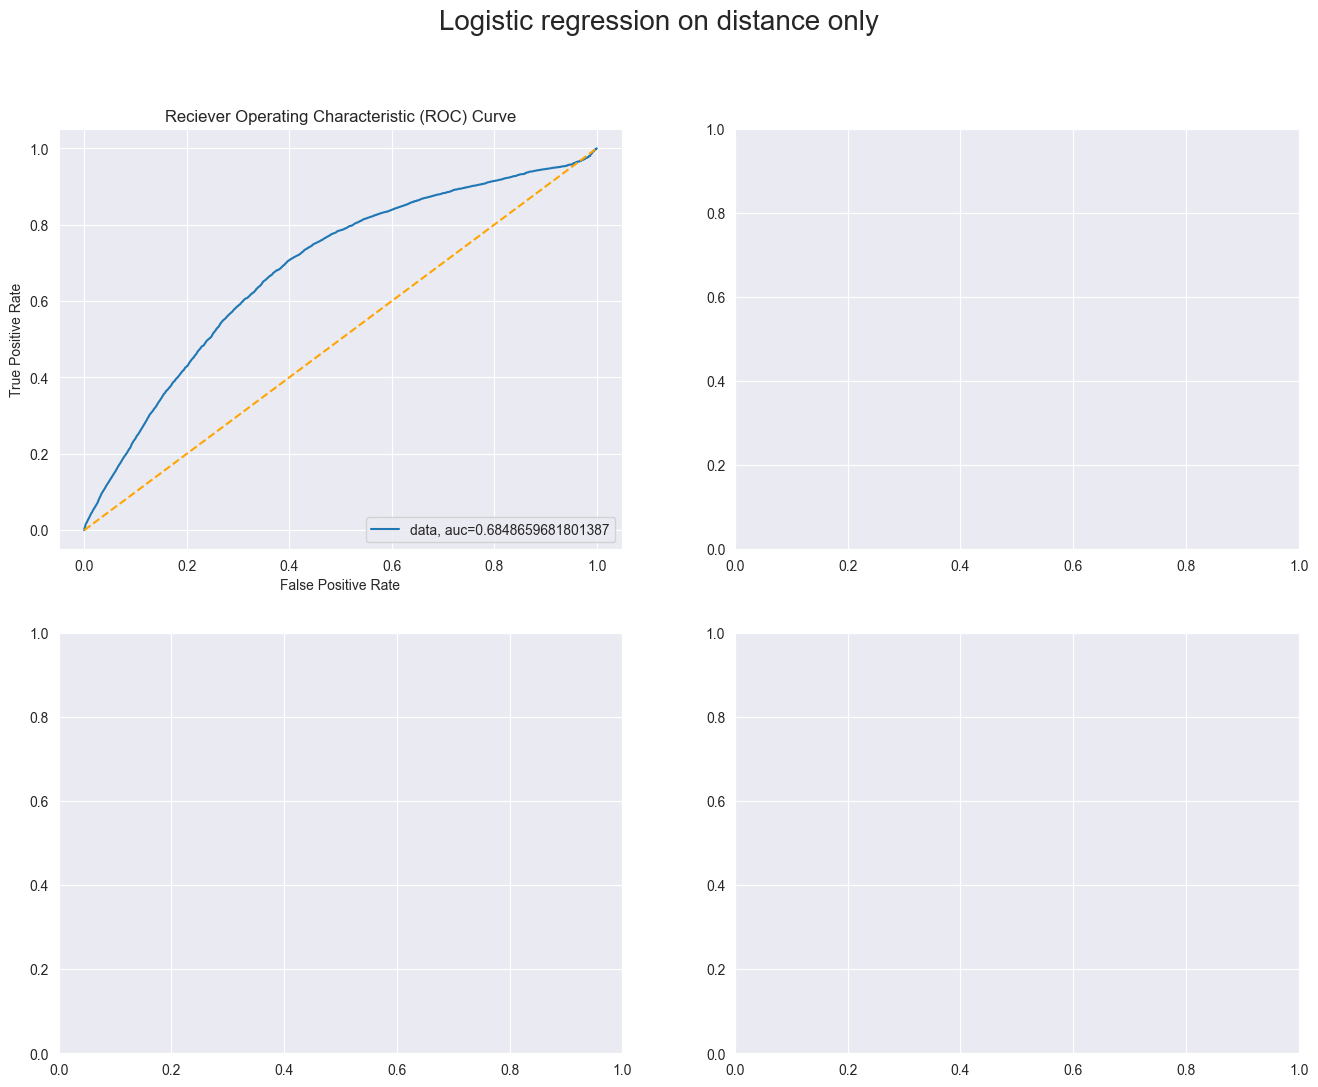

In [39]:
sns.set_style("darkgrid")
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_dist_pred_proba = model_dist.predict_proba(X_dist_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_dist_test,  y_dist_pred_proba)
auc = metrics.roc_auc_score(y_dist_test, y_dist_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Logistic regression on distance only", fontsize = 20)

In [40]:
Dict_proba = {'Goal_Proba': model_dist.predict_proba(X_dist_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba

df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

df_proba['Goals'] = y_dist_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

df_proba_sorted.reset_index(drop = True, inplace=True)
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted


df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.171826,99.999196,1,1,1,1.000000,0.00017
1,0.171826,99.999196,0,1,2,0.500000,0.00017
2,0.169967,99.995178,1,2,3,0.666667,0.00034
3,0.169967,99.995178,1,3,4,0.750000,0.00051
4,0.169967,99.995178,0,3,5,0.600000,0.00051
...,...,...,...,...,...,...,...
62212,0.003260,0.008036,1,5876,62213,0.094450,0.99983
62213,0.003258,0.006429,1,5877,62214,0.094464,1.00000
62214,0.003213,0.004822,0,5877,62215,0.094463,1.00000
62215,0.003162,0.003215,0,5877,62216,0.094461,1.00000


In [41]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [42]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

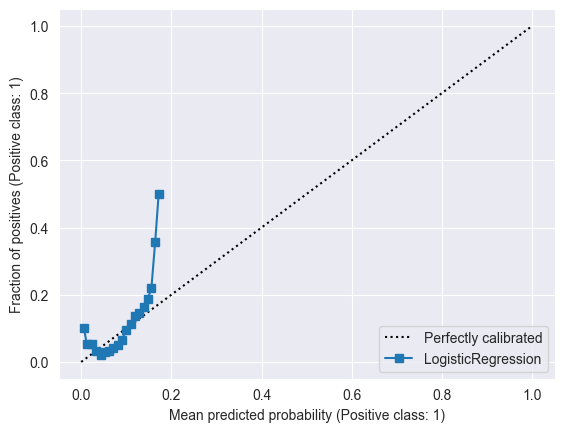

In [43]:
disp_test = CalibrationDisplay.from_estimator(model_dist,X_dist_test, y_dist_test, n_bins = 105)
disp_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

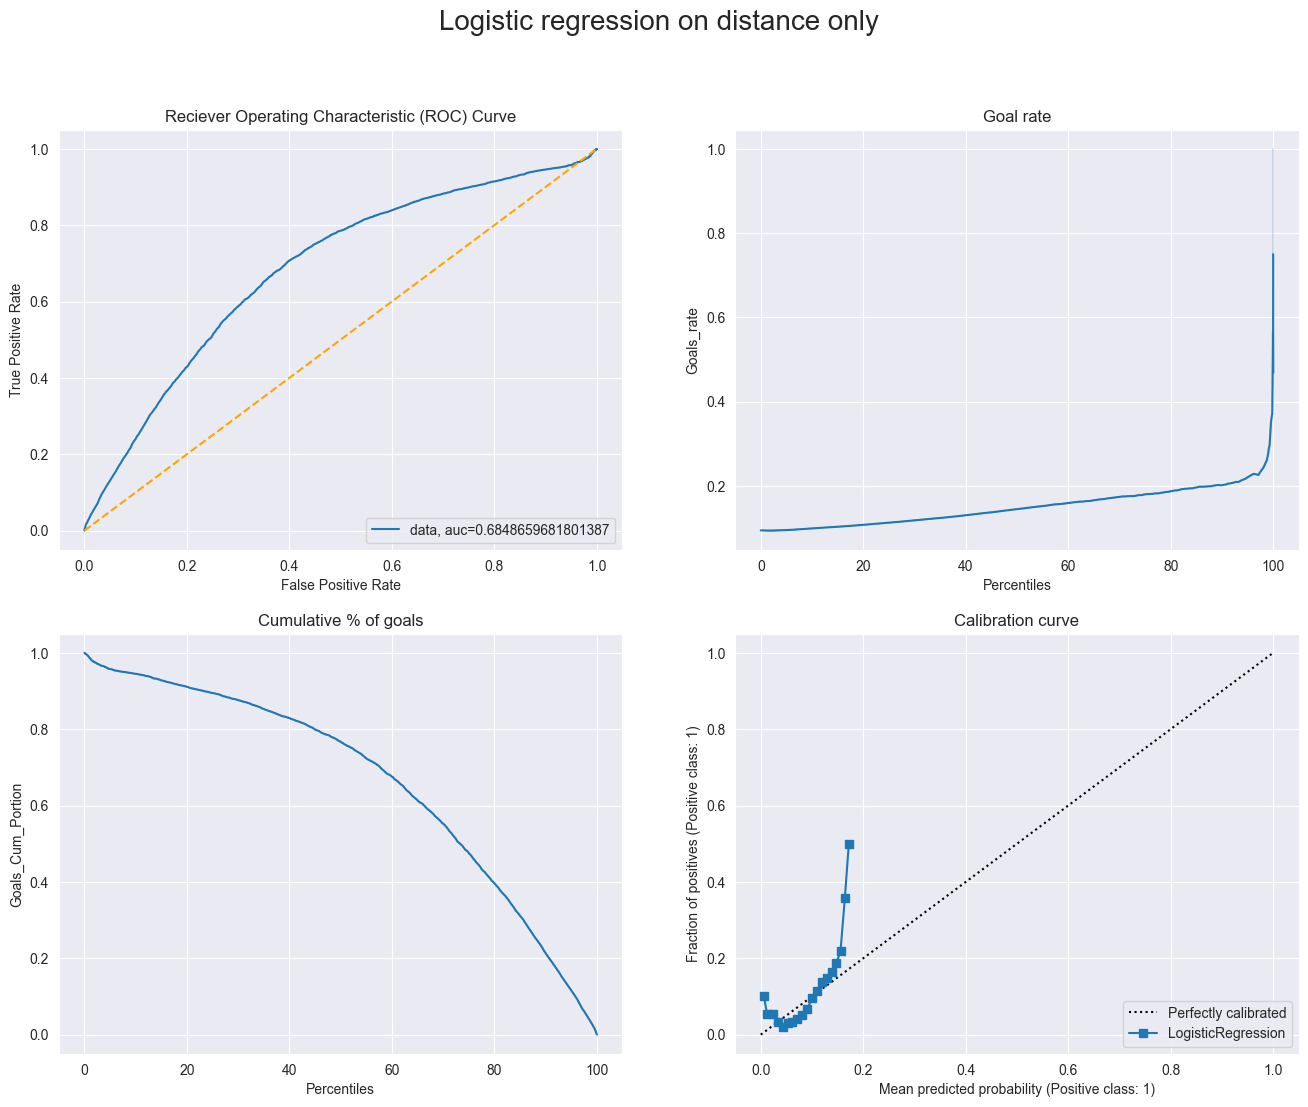

In [35]:
fig

## Model on angle only

In [44]:
X_angle = my_data[:,30]
X_angle = X_angle.reshape(-1,1)
y_angle = my_data[:, 34]
y_angle = y_angle.astype('int')
X_angle_train, X_angle_test, y_angle_train, y_angle_test = train_test_split(X_angle, y_angle, test_size = 0.20, random_state=42)
lr_angle = LogisticRegression()
model_angle = lr_angle.fit(X_angle_train,y_angle_train)
print('Accuracy on training data: ', round(model_angle.score(X_angle_train,y_angle_train),2))
result_angle = model_angle.score(X_angle_test,y_angle_test)
print('Accuracy on testing data: ', round(result_angle*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.55


Text(0.5, 0.98, 'Logistic regression on distance only')

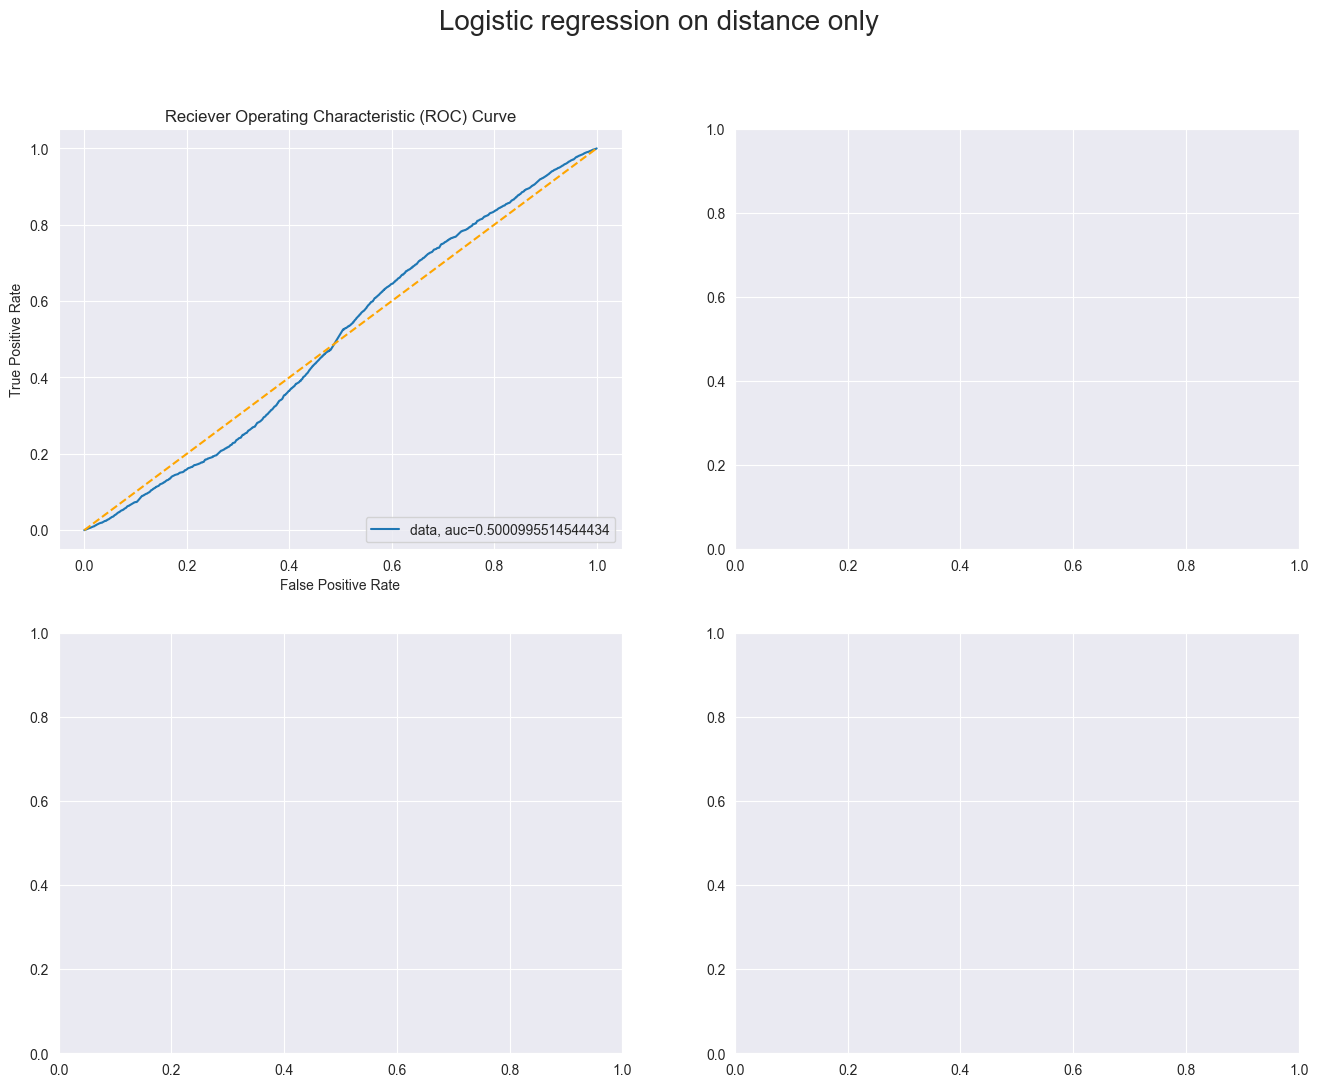

In [46]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_angle_pred_proba = model_angle.predict_proba(X_angle_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_angle_test,  y_angle_pred_proba)
auc = metrics.roc_auc_score(y_angle_test, y_angle_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Logistic regression on angle only", fontsize = 20)


In [47]:
Dict_proba_angle = {'Goal_Proba': model_angle.predict_proba(X_angle_test)[:,1]}
Dict_proba_angle
df_proba_angle = pd.DataFrame(Dict_proba_angle)
df_proba_angle

df_proba_angle['Percentiles'] = df_proba_angle.apply(lambda x: percentileofscore(df_proba_angle['Goal_Proba'],x))
df_proba_angle

df_proba_angle['Goals'] = y_angle_test
df_proba_angle_sorted = df_proba_angle.sort_values(by='Percentiles', ascending = False)
df_proba_angle_sorted

df_proba_angle_sorted['Goals_Cum'] = df_proba_angle_sorted['Goals'].cumsum()
df_proba_angle_sorted

df_proba_angle_sorted.reset_index(drop = True, inplace=True)
df_proba_angle_sorted['Event_count_cum'] = df_proba_angle_sorted.index+1
df_proba_angle_sorted


df_proba_angle_sorted = df_proba_angle_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_angle_sorted['Goals_Cum_Portion'] = df_proba_angle_sorted['Goals_Cum']/max(df_proba_angle_sorted['Goals_Cum'])
df_proba_angle_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.098109,99.961425,0,0,1,0.000000,0.00000
1,0.098109,99.961425,0,0,2,0.000000,0.00000
2,0.098109,99.961425,0,0,3,0.000000,0.00000
3,0.098109,99.961425,0,0,4,0.000000,0.00000
4,0.098109,99.961425,1,1,5,0.200000,0.00017
...,...,...,...,...,...,...,...
62212,0.089352,0.049826,0,5876,62213,0.094450,0.99983
62213,0.089352,0.049826,0,5876,62214,0.094448,0.99983
62214,0.089352,0.049826,0,5876,62215,0.094447,0.99983
62215,0.089352,0.049826,0,5876,62216,0.094445,0.99983


In [48]:
sns.lineplot(df_proba_angle_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [49]:
sns.lineplot(df_proba_angle_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

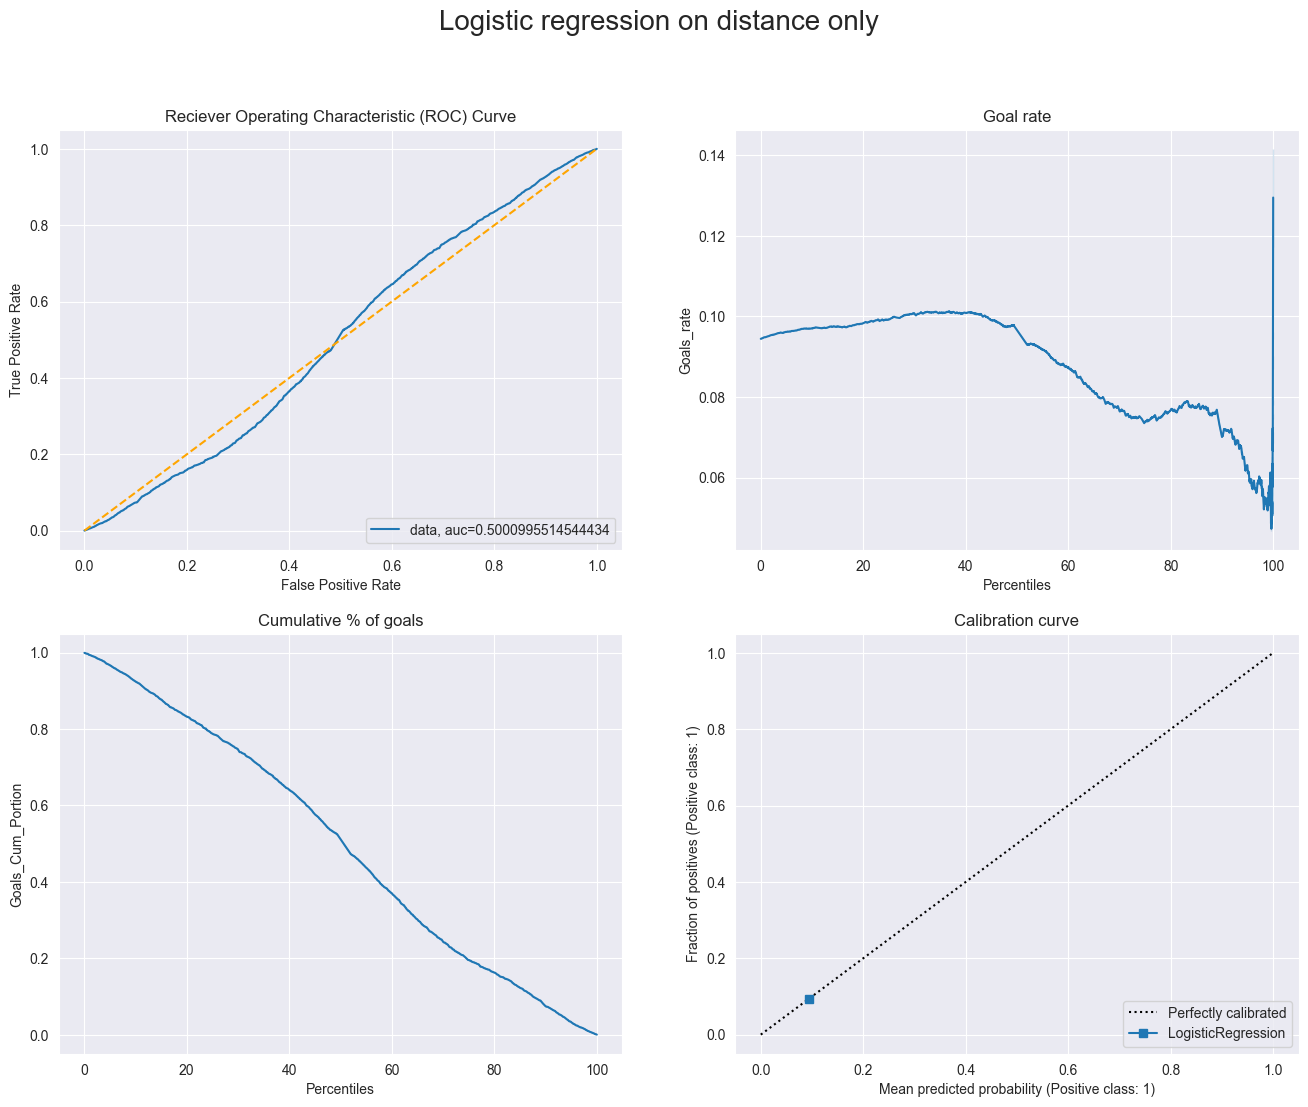

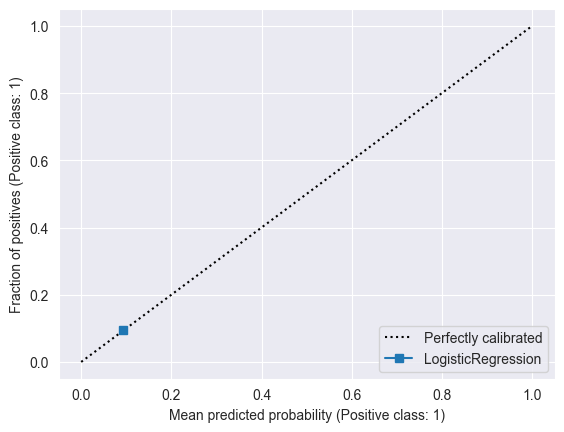

In [50]:
disp_angle_test = CalibrationDisplay.from_estimator(model_angle,X_angle_test, y_angle_test, n_bins = 10)
disp_angle_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")
fig

In [ ]:
fig

## Model on distance and angle

In [51]:
X = my_data[:,27], my_data[:,30]
X = np.asarray(X).transpose()
y = my_data[:, 34]
y = y.astype('int')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=42)
lr = LogisticRegression()
model = lr.fit(X_train,y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.55


Text(0.5, 0.98, 'Logistic regression on distance only')

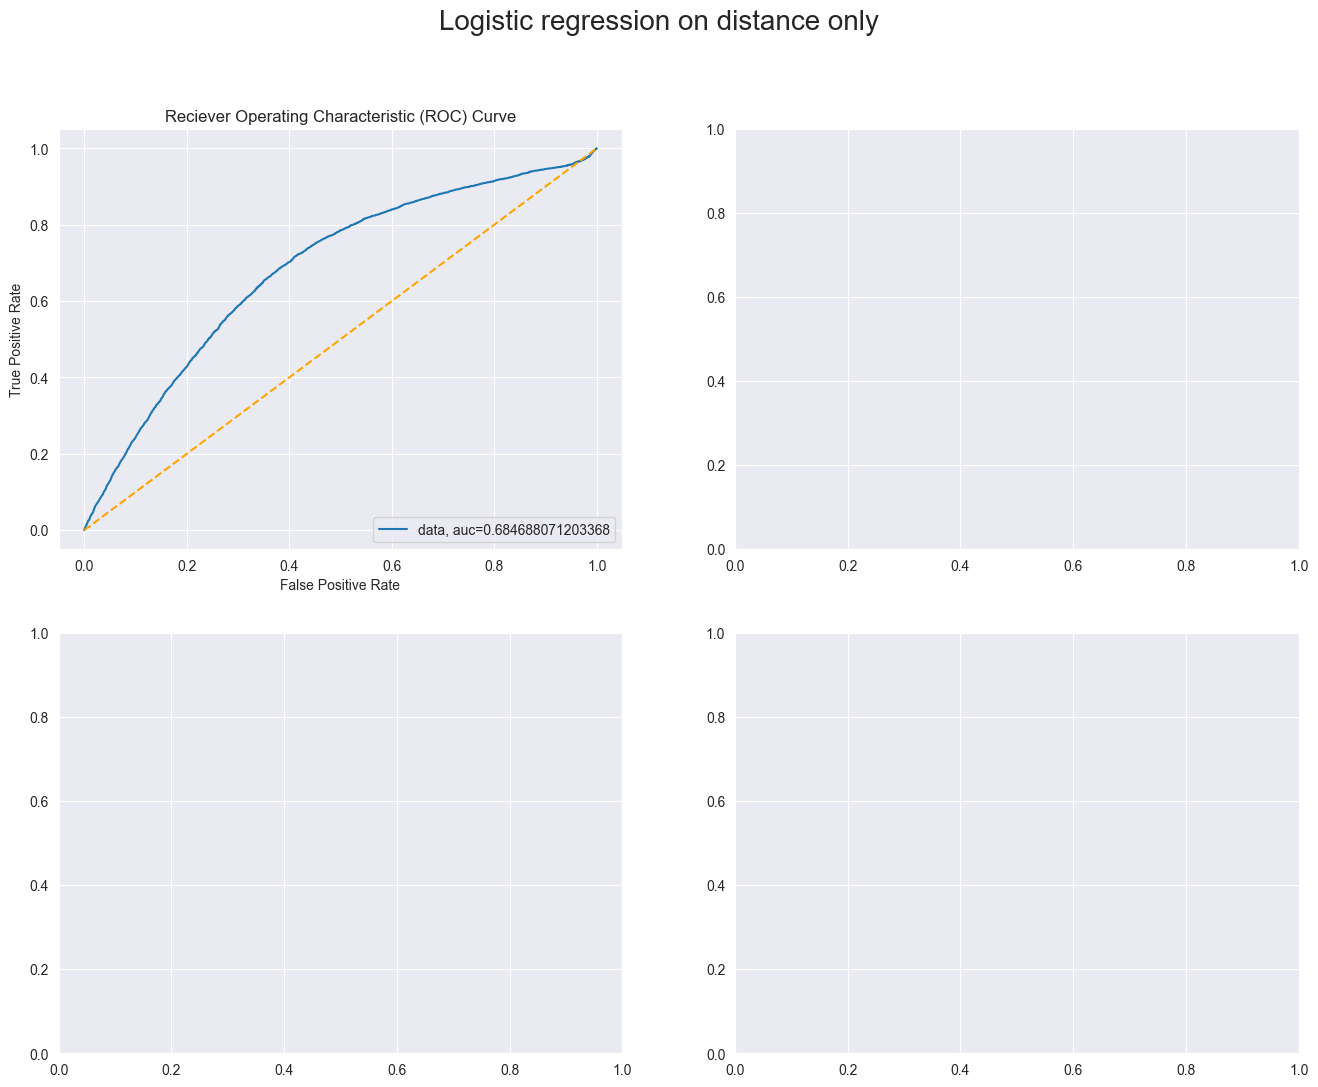

In [52]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_pred_proba = model.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Logistic regression on distance and angle", fontsize = 20)

In [53]:
Dict_proba_both = {'Goal_Proba': model.predict_proba(X_test)[:,1]}
Dict_proba_both
df_proba_both = pd.DataFrame(Dict_proba_both)
df_proba_both

df_proba_both['Percentiles'] = df_proba_both.apply(lambda x: percentileofscore(df_proba_both['Goal_Proba'],x))
df_proba_both

df_proba_both['Goals'] = y_test
df_proba_both_sorted = df_proba_both.sort_values(by='Percentiles', ascending = False)
df_proba_both_sorted

df_proba_both_sorted['Goals_Cum'] = df_proba_both_sorted['Goals'].cumsum()
df_proba_both_sorted

df_proba_both_sorted.reset_index(drop = True, inplace=True)
df_proba_both_sorted['Event_count_cum'] = df_proba_both_sorted.index+1
df_proba_both_sorted


df_proba_both_sorted = df_proba_both_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_both_sorted['Goals_Cum_Portion'] = df_proba_both_sorted['Goals_Cum']/max(df_proba_both_sorted['Goals_Cum'])
df_proba_both_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.175131,100.000000,0,0,1,0.000000,0.00000
1,0.172900,99.994375,1,1,2,0.500000,0.00017
2,0.172900,99.994375,1,2,3,0.666667,0.00034
3,0.172900,99.994375,0,2,4,0.500000,0.00034
4,0.172900,99.994375,1,3,5,0.600000,0.00051
...,...,...,...,...,...,...,...
62212,0.003240,0.008036,1,5876,62213,0.094450,0.99983
62213,0.003231,0.006429,1,5877,62214,0.094464,1.00000
62214,0.003217,0.004822,0,5877,62215,0.094463,1.00000
62215,0.003156,0.003215,0,5877,62216,0.094461,1.00000


In [54]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [55]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

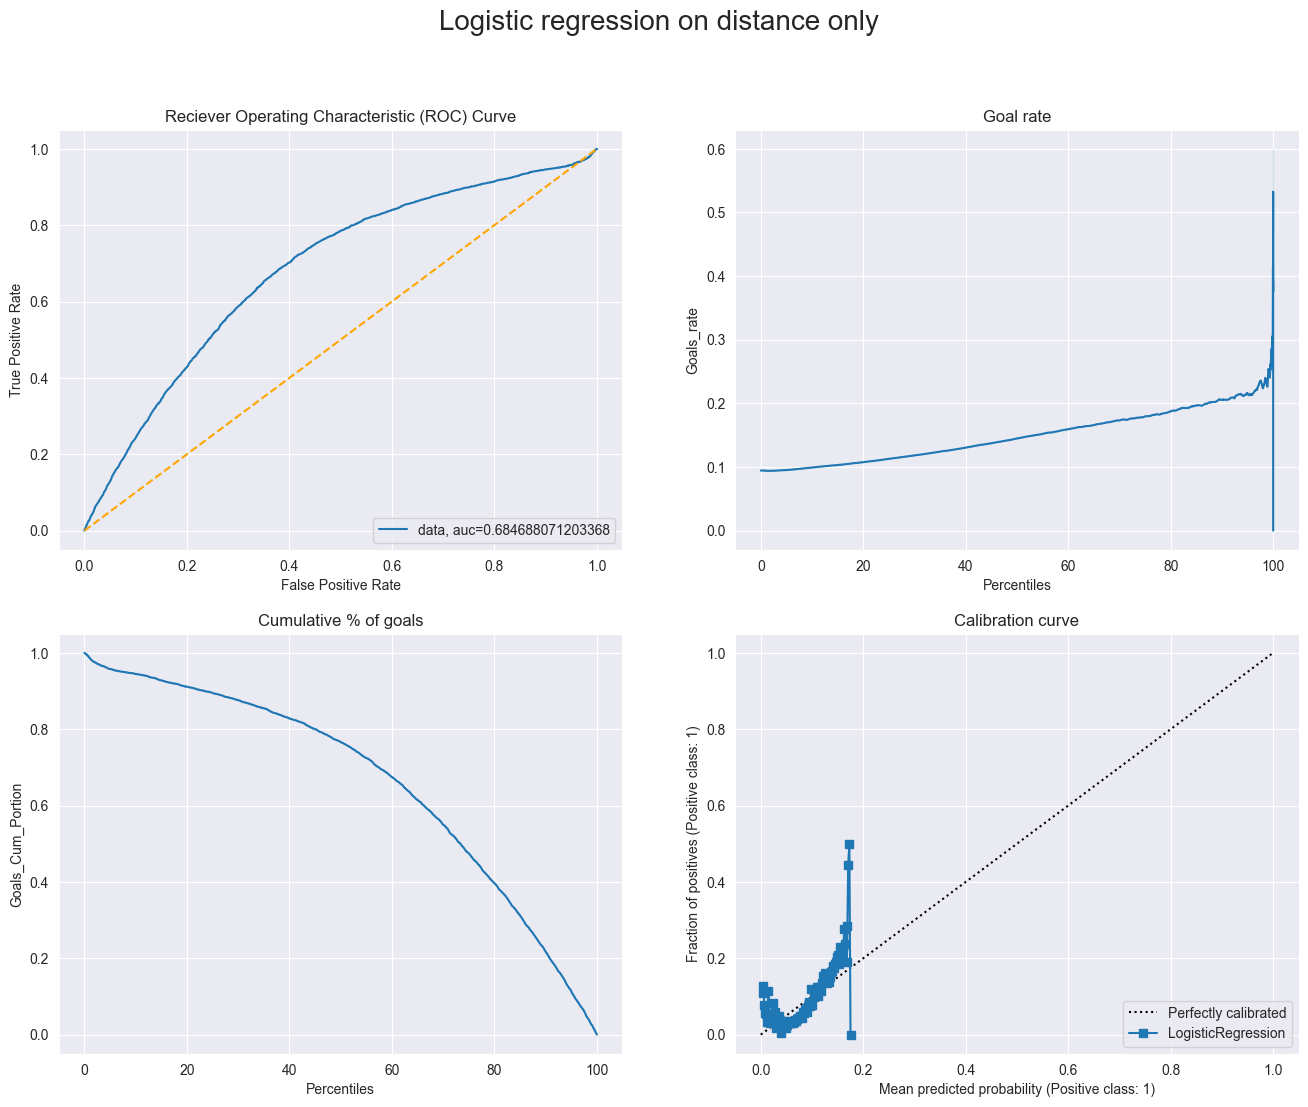

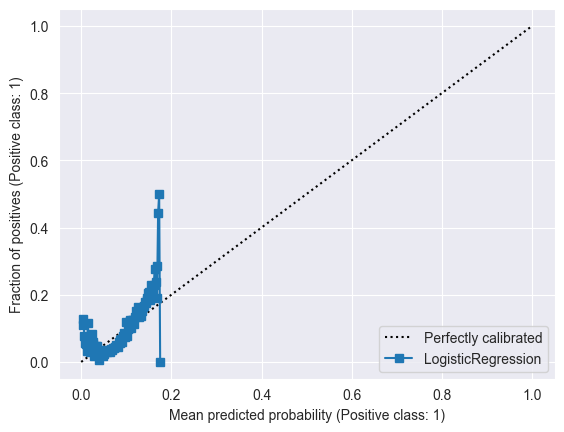

In [56]:
disp_both_test = CalibrationDisplay.from_estimator(model,X_test, y_test, n_bins = 500)
disp_both_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

In [ ]:
fig

## Random Baseline

In [62]:
y = my_data[:, 34]
y = y.astype('int')
y_train, y_test = train_test_split(y, test_size = 0.20, random_state=42)
predict_proba_train = np.random.uniform(0,1,len(y_train))
predict_proba_test = np.random.uniform(0,1,len(y_test))
acc_train = metrics.accuracy_score(y_train, predict_proba_train>=0.5)
print('Accuracy on training data: ', acc_train)
acc_test = metrics.accuracy_score(y_test, predict_proba_test>=0.5)
print('Accuracy on testing data: ', acc_test)

Accuracy on training data:  0.5001004548596043
Accuracy on testing data:  0.5010206213735796


Text(0.5, 0.98, 'Logistic regression on distance and angle')

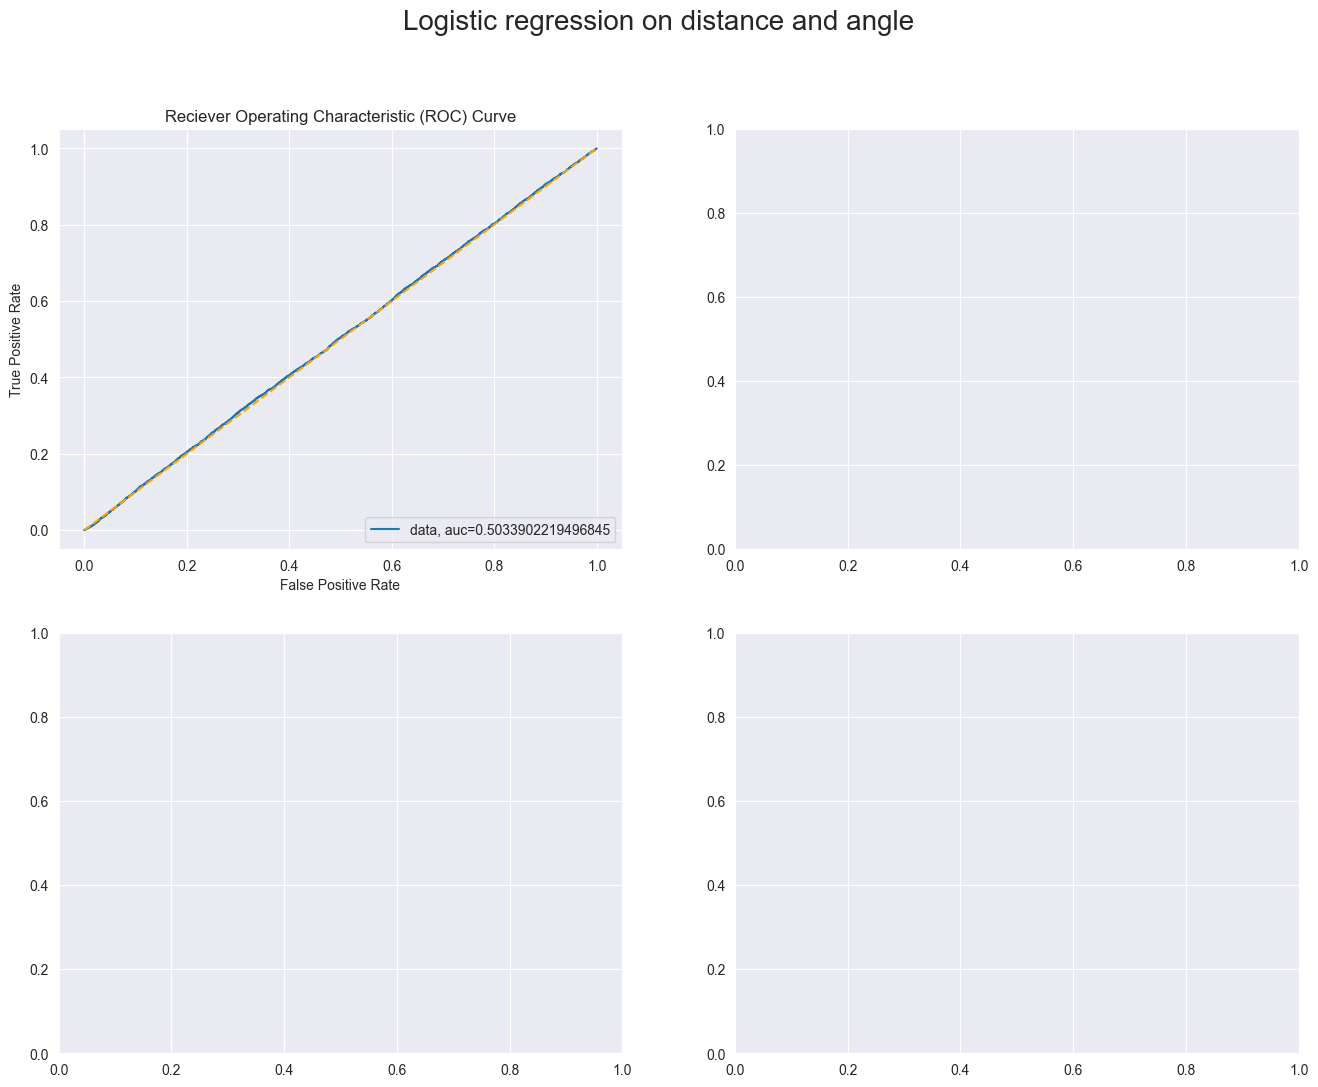

In [63]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
fpr, tpr, _ = metrics.roc_curve(y_test,  predict_proba_test)
auc = metrics.roc_auc_score(y_test, predict_proba_test)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Random uniform prediction probabilities", fontsize = 20)

In [64]:
Dict_proba_both = {'Goal_Proba':predict_proba_test}
Dict_proba_both
df_proba_both = pd.DataFrame(Dict_proba_both)
df_proba_both

df_proba_both['Percentiles'] = df_proba_both.apply(lambda x: percentileofscore(df_proba_both['Goal_Proba'],x))
df_proba_both

df_proba_both['Goals'] = y_test
df_proba_both_sorted = df_proba_both.sort_values(by='Percentiles', ascending = False)
df_proba_both_sorted

df_proba_both_sorted['Goals_Cum'] = df_proba_both_sorted['Goals'].cumsum()
df_proba_both_sorted

df_proba_both_sorted.reset_index(drop = True, inplace=True)
df_proba_both_sorted['Event_count_cum'] = df_proba_both_sorted.index+1
df_proba_both_sorted


df_proba_both_sorted = df_proba_both_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_both_sorted['Goals_Cum_Portion'] = df_proba_both_sorted['Goals_Cum']/max(df_proba_both_sorted['Goals_Cum'])
df_proba_both_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.999988,100.000000,0,0,1,0.000000,0.00000
1,0.999962,99.998393,0,0,2,0.000000,0.00000
2,0.999951,99.996785,0,0,3,0.000000,0.00000
3,0.999948,99.995178,0,0,4,0.000000,0.00000
4,0.999937,99.993571,0,0,5,0.000000,0.00000
...,...,...,...,...,...,...,...
62212,0.000170,0.008036,0,5876,62213,0.094450,0.99983
62213,0.000142,0.006429,0,5876,62214,0.094448,0.99983
62214,0.000127,0.004822,0,5876,62215,0.094447,0.99983
62215,0.000108,0.003215,1,5877,62216,0.094461,1.00000


In [65]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [66]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

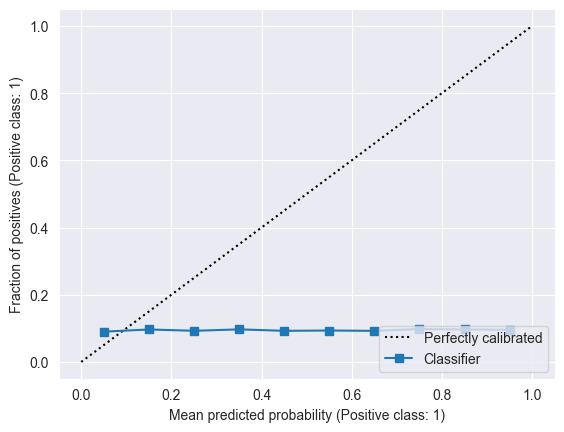

In [71]:
disp_both_test = CalibrationDisplay.from_predictions(y_test, predict_proba_test, n_bins = 10)
disp_both_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

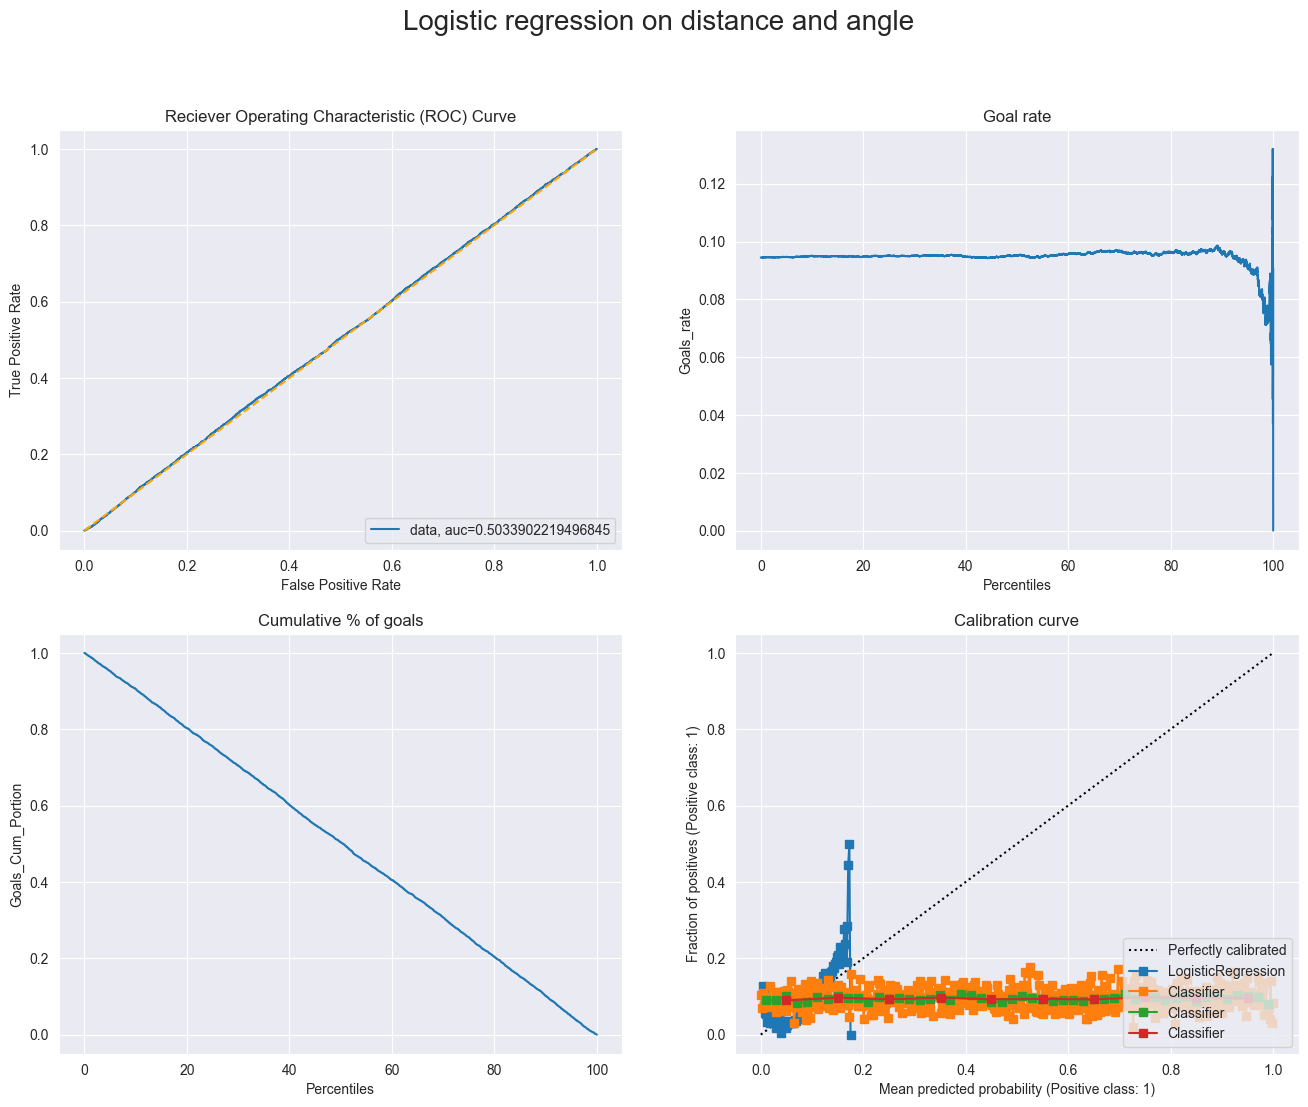

In [72]:
fig

## Predict proba (SKIP)

In [ ]:
max(model_dist.predict_proba(X_dist_test)[:,1])

In [ ]:
max(model_angle.predict_proba(X_dist_test)[:,1])

In [ ]:
max(model.predict_proba(X_test)[:,1])

In [ ]:
df_model

In [ ]:
df_model[df_model['Event_Type_Binary']==1]['Event_Type_Binary'].count()/df_model['Event_Type_Binary'].count()

In [ ]:
df_model['Event_Type_Binary'].count()

In [ ]:
X_test

In [ ]:
#np.random.uniform(14000,0,1)
## Percentiles

In [ ]:
Dict_proba = {'Goal_Proba': model_dist.predict_proba(X_dist_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba
from scipy.stats import percentileofscore
df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

In [ ]:
y_dist_test

In [ ]:
df_proba['Goals'] = y_dist_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

In [ ]:
df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

In [ ]:
df_proba_sorted.reset_index(drop = True, inplace=True)

In [ ]:
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted

In [ ]:
df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

In [ ]:
df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

In [ ]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate')

In [ ]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion')

In [ ]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
y_dist_prob = model_dist.predict_proba(X_dist_test)[:,1]
prob_dist_true, prob_dist_pred = calibration_curve(y_dist_test, y_dist_prob, n_bins = 50)
disp_dist = CalibrationDisplay(prob_dist_true, prob_dist_pred, y_dist_prob)
disp_dist.plot()

In [ ]:
disp_test = CalibrationDisplay.from_estimator(model_dist,X_dist_test, y_dist_test, n_bins = 105)
plt.show()

In [131]:
df_model[df_model['Event_Type_Binary']==1]['Event_Type_Binary'].count()/df_model['Event_Type_Binary'].count()

0.09378465692656347

In [132]:
df_model['Event_Type_Binary'].count()

311085

In [133]:
X_test

array([[49.51767361255979, 43.36342295838328],
       [29.410882339705484, -35.31121343963321],
       [50.20956084253277, 44.19307054489763],
       ...,
       [15.297058540778355, 78.69006752597979],
       [60.41522986797286, -24.443954780416536],
       [89.98888820293314, -14.808377039042396]], dtype=object)

In [ ]:
#np.random.uniform(14000,0,1)
## Percentiles

In [18]:
Dict_proba = {'Goal_Proba': model_dist.predict_proba(X_dist_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba
from scipy.stats import percentileofscore
df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

,Goal_Proba,Percentiles
0,0.066063,26.459006
1,0.100070,57.368565
2,0.065109,25.506694
3,0.154656,97.113329
4,0.073693,33.598534
...,...,...
62212,0.107031,62.397737
62213,0.025674,4.355723
62214,0.132514,78.477747
62215,0.052452,11.189868


In [60]:
y_dist_test

array([0, 0, 0, ..., 0, 0, 0])

In [61]:
df_proba['Goals'] = y_dist_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

,Goal_Proba,Percentiles,Goals
39426,0.174041,100.000000,1
41184,0.172706,99.998393,1
22071,0.170831,99.995178,0
28598,0.170831,99.995178,1
47884,0.170831,99.995178,0
...,...,...,...
20503,0.003203,0.007233,0
19788,0.003203,0.007233,1
41692,0.003193,0.004822,0
32053,0.003169,0.003215,0


In [62]:
df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum
39426,0.174041,100.000000,1,1
41184,0.172706,99.998393,1,2
22071,0.170831,99.995178,0,2
28598,0.170831,99.995178,1,3
47884,0.170831,99.995178,0,3
...,...,...,...,...
20503,0.003203,0.007233,0,5795
19788,0.003203,0.007233,1,5796
41692,0.003193,0.004822,0,5796
32053,0.003169,0.003215,0,5796


In [63]:
df_proba_sorted.reset_index(drop = True, inplace=True)

In [64]:
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum
0,0.174041,100.000000,1,1,1
1,0.172706,99.998393,1,2,2
2,0.170831,99.995178,0,2,3
3,0.170831,99.995178,1,3,4
4,0.170831,99.995178,0,3,5
...,...,...,...,...,...
62212,0.003203,0.007233,0,5795,62213
62213,0.003203,0.007233,1,5796,62214
62214,0.003193,0.004822,0,5796,62215
62215,0.003169,0.003215,0,5796,62216


In [65]:
df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

In [66]:
df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.174041,100.000000,1,1,1,1.000000,0.000173
1,0.172706,99.998393,1,2,2,1.000000,0.000345
2,0.170831,99.995178,0,2,3,0.666667,0.000345
3,0.170831,99.995178,1,3,4,0.750000,0.000518
4,0.170831,99.995178,0,3,5,0.600000,0.000518
...,...,...,...,...,...,...,...
62212,0.003203,0.007233,0,5795,62213,0.093148,0.999827
62213,0.003203,0.007233,1,5796,62214,0.093162,1.000000
62214,0.003193,0.004822,0,5796,62215,0.093161,1.000000
62215,0.003169,0.003215,0,5796,62216,0.093159,1.000000


<AxesSubplot: xlabel='Percentiles', ylabel='Goals_rate'>

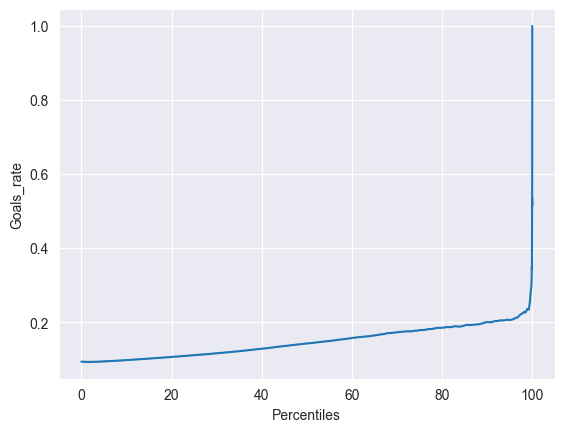

In [67]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate')

<AxesSubplot: xlabel='Percentiles', ylabel='Goals_Cum_Portion'>

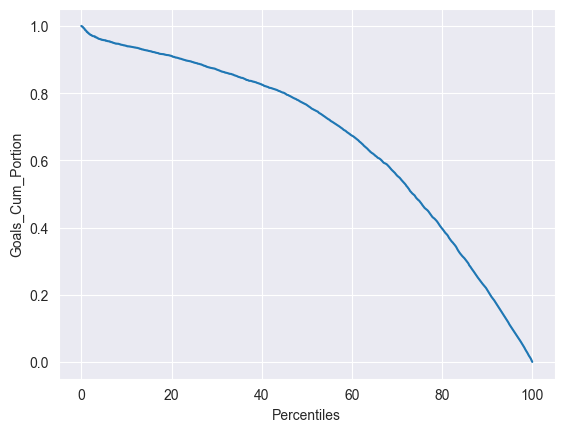

In [68]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion')

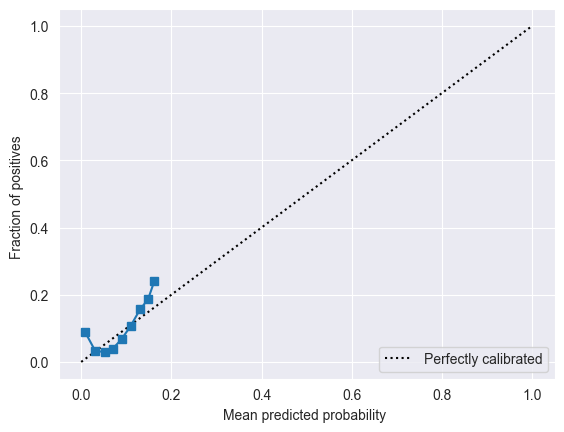

In [94]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
y_dist_prob = model_dist.predict_proba(X_dist_test)[:,1]
prob_dist_true, prob_dist_pred = calibration_curve(y_dist_test, y_dist_prob, n_bins = 50)
disp_dist = CalibrationDisplay(prob_dist_true, prob_dist_pred, y_dist_prob)
disp_dist.plot()

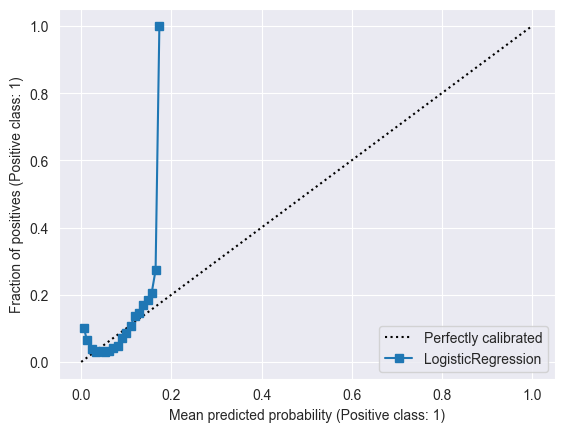

In [108]:
disp_test = CalibrationDisplay.from_estimator(model_dist,X_dist_test, y_dist_test, n_bins = 105)
plt.show()